# 02 – Preprocessing and Isolation Forest prototype

Case study *Early Warning of Air-Leak Failures in Metro Compressors* (Group 6, MDM2, TH Deggendorf).

This notebook belongs to the methodology milestone. It runs the preprocessing pipeline and a first learned detector:

1. Remove frozen logging segments
2. Build gap-aware 10-minute windows
3. Chronological split (train = February 2020)
4. Scale with training statistics only
5. Isolation Forest (Liu et al., 2008)
6. Common alarm logic: threshold Q3 + 3·IQR (Silva et al., 2023) and a low-pass filter (Ribeiro et al., 2016)
7. Event-level evaluation, also against the first LPS activation
8. Comparison with the threshold baseline and with/without frozen-segment masking

Code: `src/preprocessing.py`, `src/detectors.py`, `src/alarm_logic.py`, `src/evaluation.py`, `src/run_experiment.py`.

Data: Davari, N., Veloso, B., Ribeiro, R., & Gama, J. (2021). *MetroPT-3 Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5VW3R (CC BY 4.0). Run `python scripts/download_data.py` first, or use the Colab cell below.

In [1]:
# Google Colab only: clone the repository and download the data
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo_dir = "/content/IntelligentSystemsCaseStudy"
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "https://github.com/mohamedfarez/IntelligentSystemsCaseStudy.git", repo_dir], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True)

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import src
from src import config
from src.data_loading import load_metropt3
from src.evaluation import evaluate_events, lps_onsets
from src.preprocessing import PreprocessConfig, prepare
from src.run_experiment import run
from src.threshold_baseline import run_baseline

print("project code version:", src.__version__)
config.set_global_seed()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

def save(fig, name):
    fig.savefig(config.figure_path(name), dpi=150, bbox_inches="tight")

def shade_failures(ax):
    for _, p in config.FAILURE_PERIODS.iterrows():
        ax.axvspan(p["start"], p["end"], color="red", alpha=0.25, lw=0)

project code version: 0.3.0


In [3]:
df = load_metropt3()
print(df.shape, df.index.min(), "->", df.index.max())

(1516948, 15) 2020-02-01 00:00:00 -> 2020-09-01 03:59:50


## 1. Frozen segments

Records in which all analogue signals stay exactly the same for at least 30 minutes are removed (see notebook 01, section 2b).

In [4]:
pre_cfg = PreprocessConfig()
data = prepare(df, pre_cfg)
print(f"Frozen segments: {len(data.frozen_segments)}, records removed: {data.n_records_removed:,} "
      f"({100 * data.n_records_removed / len(df):.1f} %)")
data.frozen_segments

Frozen segments: 9, records removed: 50,716 (3.3 %)


,start,end,duration,n_records
0,2020-04-13 18:29:10,2020-04-13 19:27:16,0 days 00:58:06,291
1,2020-04-17 09:20:33,2020-04-18 00:18:07,0 days 14:57:34,4470
2,2020-04-20 04:49:07,2020-04-21 01:16:52,0 days 20:27:45,6110
3,2020-05-26 09:19:26,2020-05-27 13:43:45,1 days 04:24:19,8466
4,2020-05-27 13:53:52,2020-05-28 03:16:28,0 days 13:22:36,3983
5,2020-06-12 02:01:46,2020-06-12 17:06:06,0 days 15:04:20,4502
6,2020-06-22 15:06:11,2020-06-25 05:08:35,2 days 14:02:24,18515
7,2020-07-21 13:45:02,2020-07-21 22:03:16,0 days 08:18:14,2481
8,2020-07-22 06:43:34,2020-07-22 13:04:24,0 days 06:20:50,1898


## 2. Gap-aware windows

Features per 10-minute window: mean, std, min and max of the 7 analogue signals, the share of active time of the digital signals (without LPS, which we keep for the evaluation), and the share of time under load. A window is kept only if it has at least 50 % of the expected records (60 at 10 s), so gaps are not filled with made-up values.

Windows kept: 24,235 | features: 36


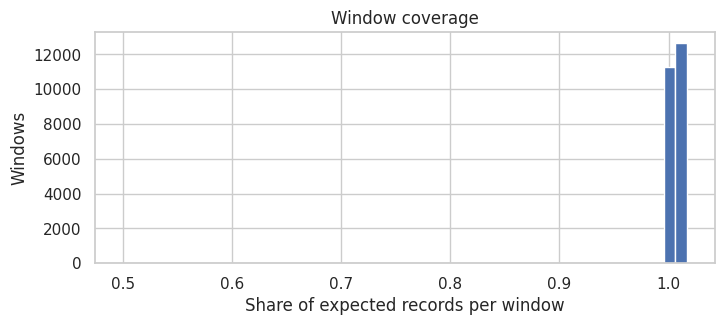

In [5]:
feats = data.features
print(f"Windows kept: {len(feats):,} | features: {data.train.shape[1]}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(feats["coverage"], bins=50)
ax.set(xlabel="Share of expected records per window", ylabel="Windows", title="Window coverage")
save(fig, "prep_01_window_coverage")
plt.show()

## 3. Chronological split and 4. scaling

Train = windows ending on or before 1 March 2020. The scaler is fitted on these windows only. If the test months behave like February, the scaled test features should also have mean ≈ 0 and std ≈ 1. The plot shows how far each feature moves away from that (the February shift seen in notebook 01).

Train windows: 3,552  (2020-02-01 00:10:00 -> 2020-02-29 00:00:00)
Test windows:  20,683  (2020-03-01 04:10:00 -> 2020-09-01 04:00:00)


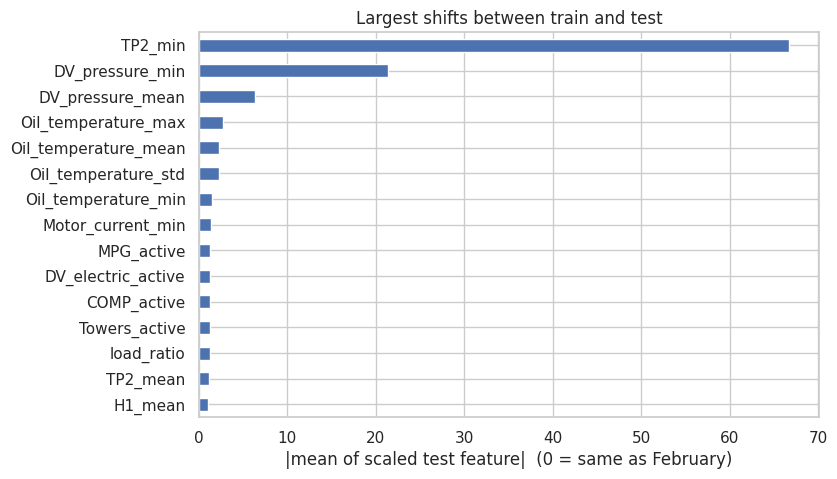

In [6]:
print(f"Train windows: {len(data.train):,}  ({data.train.index.min()} -> {data.train.index.max()})")
print(f"Test windows:  {len(data.test):,}  ({data.test.index.min()} -> {data.test.index.max()})")

shift = data.test.mean().abs().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
shift.head(15)[::-1].plot.barh(ax=ax)
ax.set(xlabel="|mean of scaled test feature|  (0 = same as February)", title="Largest shifts between train and test")
save(fig, "prep_02_feature_shift")
plt.show()

## 5. Isolation Forest and 6. alarm logic

Threshold (Q3 + 3*IQR of training scores): 0.6371
Test windows above threshold: 9.8%


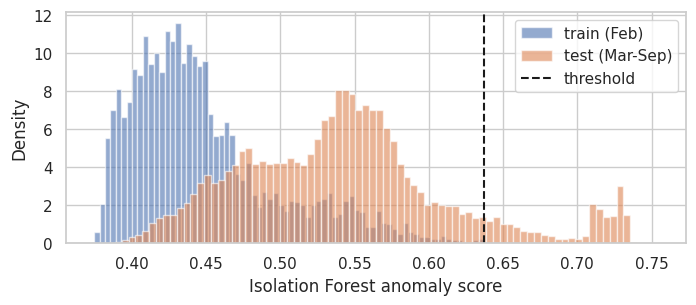

In [7]:
out = run(df, "iforest", pre_cfg)
rule = out["rule"]
print("Threshold (Q3 + 3*IQR of training scores):", round(rule.threshold_, 4))
print("Test windows above threshold:", f"{(out['test_scores'] > rule.threshold_).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(out["train_scores"], bins=80, alpha=0.6, density=True, label="train (Feb)")
ax.hist(out["test_scores"], bins=80, alpha=0.6, density=True, label="test (Mar-Sep)")
ax.axvline(rule.threshold_, color="k", ls="--", label="threshold")
ax.set(xlabel="Isolation Forest anomaly score", ylabel="Density")
ax.legend()
save(fig, "iforest_01_score_distribution")
plt.show()

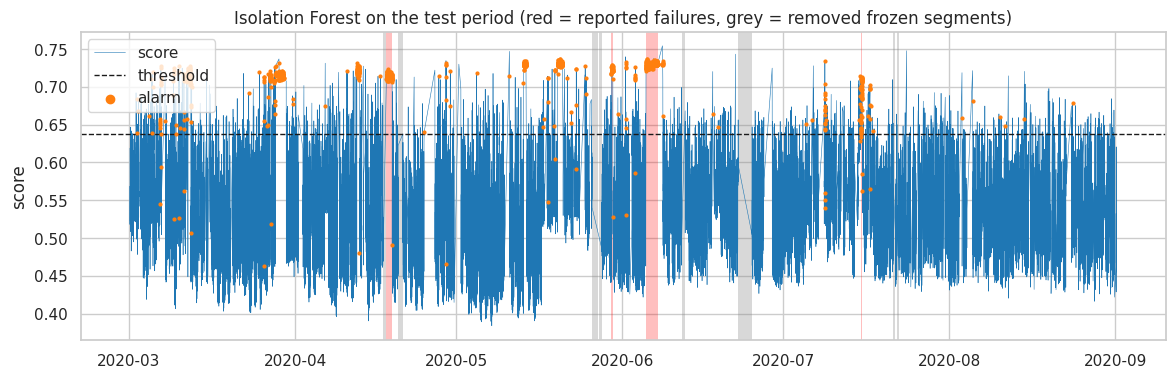

In [8]:
scores, alarms = out["test_scores"], out["alarms"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(scores.index, scores, lw=0.4, color="tab:blue", label="score")
ax.axhline(rule.threshold_, color="k", ls="--", lw=1, label="threshold")
ax.scatter(alarms.index[alarms], scores[alarms], s=4, color="tab:orange", label="alarm", zorder=3)
shade_failures(ax)
for _, s in data.frozen_segments.iterrows():
    ax.axvspan(s["start"], s["end"], color="grey", alpha=0.3, lw=0)
ax.set(title="Isolation Forest on the test period (red = reported failures, grey = removed frozen segments)", ylabel="score")
ax.legend(loc="upper left", markerscale=3)
save(fig, "iforest_02_alarms_test_period")
plt.show()

## 7. Event-level evaluation

`lead_time_min` is measured to the reported failure start; `lead_vs_lps_min` to the first LPS activation within [start − 2 h, end]. Positive values mean the alarm came earlier.

In [9]:
out["events"]

,failure_id,start,end,detected,first_alarm,lead_time_min,early_warning,lps_onset,lead_vs_lps_min
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,True,2020-04-18 00:40:00,-40.0,False,NaT,NaN
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,True,2020-05-29 23:30:00,0.0,False,NaT,NaN
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,True,2020-06-05 10:10:00,-10.0,False,2020-06-06 19:42:19,2012.316667
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,True,2020-07-15 12:30:00,120.0,True,2020-07-15 17:20:11,290.183333


In [10]:
lps = lps_onsets(df)
print("First LPS activation per failure:")
print(lps.to_string())

First LPS activation per failure:
1                   NaT
2                   NaT
3   2020-06-06 19:42:19
4   2020-07-15 17:20:11


## 8. Comparison

Same test period, same horizon (2 h), same event-level metrics. The baseline keeps its own rules (notebook 01); Isolation Forest uses the common alarm logic. The last column repeats the Isolation Forest run without removing frozen segments.

In [11]:
base = run_baseline(df)
_, base_summary = evaluate_events(base["alarms"], "2h", "10min", lps=lps)
nomask = run(df, "iforest", PreprocessConfig(mask_frozen=False))

comparison = pd.DataFrame({
    "threshold_baseline": base_summary,
    "iforest": out["summary"],
    "iforest_no_frozen_mask": nomask["summary"],
}).round(3)
comparison

,threshold_baseline,iforest,iforest_no_frozen_mask
n_failures,4.000,4.000,4.000
n_detected,4.000,4.000,4.000
n_early_warnings,1.000,1.000,1.000
event_recall,1.000,1.000,1.000
median_lead_time_min,-20.000,-5.000,-5.000
n_alarm_episodes,51.000,102.000,106.000
n_false_alarm_episodes,45.000,96.000,100.000
false_alarms_per_day,0.245,0.522,0.543
window_precision,0.324,0.421,0.290
window_recall,0.911,0.947,0.921


In [12]:
lead = pd.DataFrame({
    "baseline": base["events"].set_index("failure_id")["lead_time_min"],
    "iforest": out["events"].set_index("failure_id")["lead_time_min"],
    "iforest_no_mask": nomask["events"].set_index("failure_id")["lead_time_min"],
})
lead

,baseline,iforest,iforest_no_mask
failure_id,,,
1,-50.0,-40.0,-40.0
2,-20.0,0.0,0.0
3,-20.0,-10.0,-10.0
4,120.0,120.0,120.0


In [13]:
out["events"].to_csv(config.RESULTS_DIR / "iforest_events.csv", index=False)
pd.Series(out["summary"]).to_csv(config.RESULTS_DIR / "iforest_summary.csv", header=["value"])
comparison.to_csv(config.RESULTS_DIR / "detector_comparison.csv")
lead.to_csv(config.RESULTS_DIR / "lead_time_comparison.csv")
print("saved to", config.RESULTS_DIR)

saved to /content/IntelligentSystemsCaseStudy/results


## 9. Notes

This is a first prototype with default settings: no parameter was tuned on the test period. Sensitivity of window length, IQR factor and filter length, the LSTM autoencoder and SHAP explanations follow in the next milestone.